# 01_ EDA

In [ ]:
#Importación de pandas y lectura del csv

import pandas as pd
heart=pd.read_csv(r"..data\raw\Medicaldataset.csv")#leer datos del raw.
heart.shape

(1319, 9)

9 variables de las cuales una es la objetivo, 1.319 muestras distintas. No se trata de un dataset muy grande por lo que pueden ser necesarios modelos simples. LAs variables en inglés modelan lo siguiente:

Age: The patient's age

Gender: Biological sex of the patient (The male is set to 1 and the female to 0)

Heart Rate: The number of heartbeats per minute

Systolic Blood Pressure: The pressure in arteries when the heart contracts

Diastolic Blood Pressure: The pressure in arteries between heartbeats

Blood Sugar: The patient's blood glucose level

Ck-mb: A cardiac enzyme released during heart muscle damage

Troponin:A highly specific protein biomarker for heart muscle injury

Result: The outcome label indicating whether or not the patient experienced a heart attack

In [2]:
#Analisis inicial:
heart=heart.drop_duplicates()
heart.describe()

,Age,Gender,Heart rate,Systolic blood pressure,Diastolic blood pressure,Blood sugar,CK-MB,Troponin
count,1319.000000,1319.000000,1319.000000,1319.000000,1319.000000,1319.000000,1319.000000,1319.000000
mean,56.191812,0.659591,78.336619,127.170584,72.269143,146.634344,15.274306,0.360942
std,13.647315,0.474027,51.630270,26.122720,14.033924,74.923045,46.327083,1.154568
min,14.000000,0.000000,20.000000,42.000000,38.000000,35.000000,0.321000,0.001000
25%,47.000000,0.000000,64.000000,110.000000,62.000000,98.000000,1.655000,0.006000
50%,58.000000,1.000000,74.000000,124.000000,72.000000,116.000000,2.850000,0.014000
75%,65.000000,1.000000,85.000000,143.000000,81.000000,169.500000,5.805000,0.085500
max,103.000000,1.000000,1111.000000,223.000000,154.000000,541.000000,300.000000,10.300000


Parece ser que existen variables con outliers extremadamente grandes como CK-MB o Troponin. Luego eso es algo que deberemos estudiar

In [3]:
heart.head()

,Age,Gender,Heart rate,Systolic blood pressure,Diastolic blood pressure,Blood sugar,CK-MB,Troponin,Result
0,64,1,66,160,83,160.0,1.80,0.012,negative
1,21,1,94,98,46,296.0,6.75,1.060,positive
2,55,1,64,160,77,270.0,1.99,0.003,negative
3,64,1,70,120,55,270.0,13.87,0.122,positive
4,55,1,64,112,65,300.0,1.08,0.003,negative


Debemos pasar la columna objetivo a una numerica para ver las correlaciones, de esta manera, veremos si existen avriables altamente correlacionadas que debamos eliminar.

In [4]:
#Nos aseguramos que exista una buena distribución de clases
heart.Result.value_counts()

Result
positive    810
negative    509
Name: count, dtype: int64

In [5]:
def obj(data):
    if data.Result== "positive":
     return 1
    else: 
     return 0

heart['target']=heart.apply(obj,axis=1)
heart=heart.drop(columns=['Result'])

In [6]:
#Introducimos las correlaciones para ver si existen variables extremadamente correlacionadas
cor=heart.corr()
cor

,Age,Gender,Heart rate,Systolic blood pressure,Diastolic blood pressure,Blood sugar,CK-MB,Troponin,target
Age,1.000000,-0.092874,-0.023440,0.017441,0.002614,-0.004193,0.018419,0.088800,0.238097
Gender,-0.092874,1.000000,-0.026781,0.011065,-0.009370,0.006668,0.017527,0.065793,0.094432
Heart rate,-0.023440,-0.026781,1.000000,0.010882,0.108353,-0.019584,-0.013001,0.011180,0.006920
Systolic blood pressure,0.017441,0.011065,0.010882,1.000000,0.586166,0.020807,-0.016396,0.043729,-0.020825
Diastolic blood pressure,0.002614,-0.009370,0.108353,0.586166,1.000000,-0.025614,-0.023403,0.043360,-0.009659
Blood sugar,-0.004193,0.006668,-0.019584,0.020807,-0.025614,1.000000,0.045757,0.021069,-0.033059
CK-MB,0.018419,0.017527,-0.013001,-0.016396,-0.023403,0.045757,1.000000,-0.016008,0.217720
Troponin,0.088800,0.065793,0.011180,0.043729,0.043360,0.021069,-0.016008,1.000000,0.229376
target,0.238097,0.094432,0.006920,-0.020825,-0.009659,-0.033059,0.217720,0.229376,1.000000


A priori, las variables no tienen mucha correlación. 

Veamos a continuación los valores extremos utilizando boxplot.

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt

In [8]:
heart.columns


Index(['Age', 'Gender', 'Heart rate', 'Systolic blood pressure',
       'Diastolic blood pressure', 'Blood sugar', 'CK-MB', 'Troponin',
       'target'],
      dtype='str')

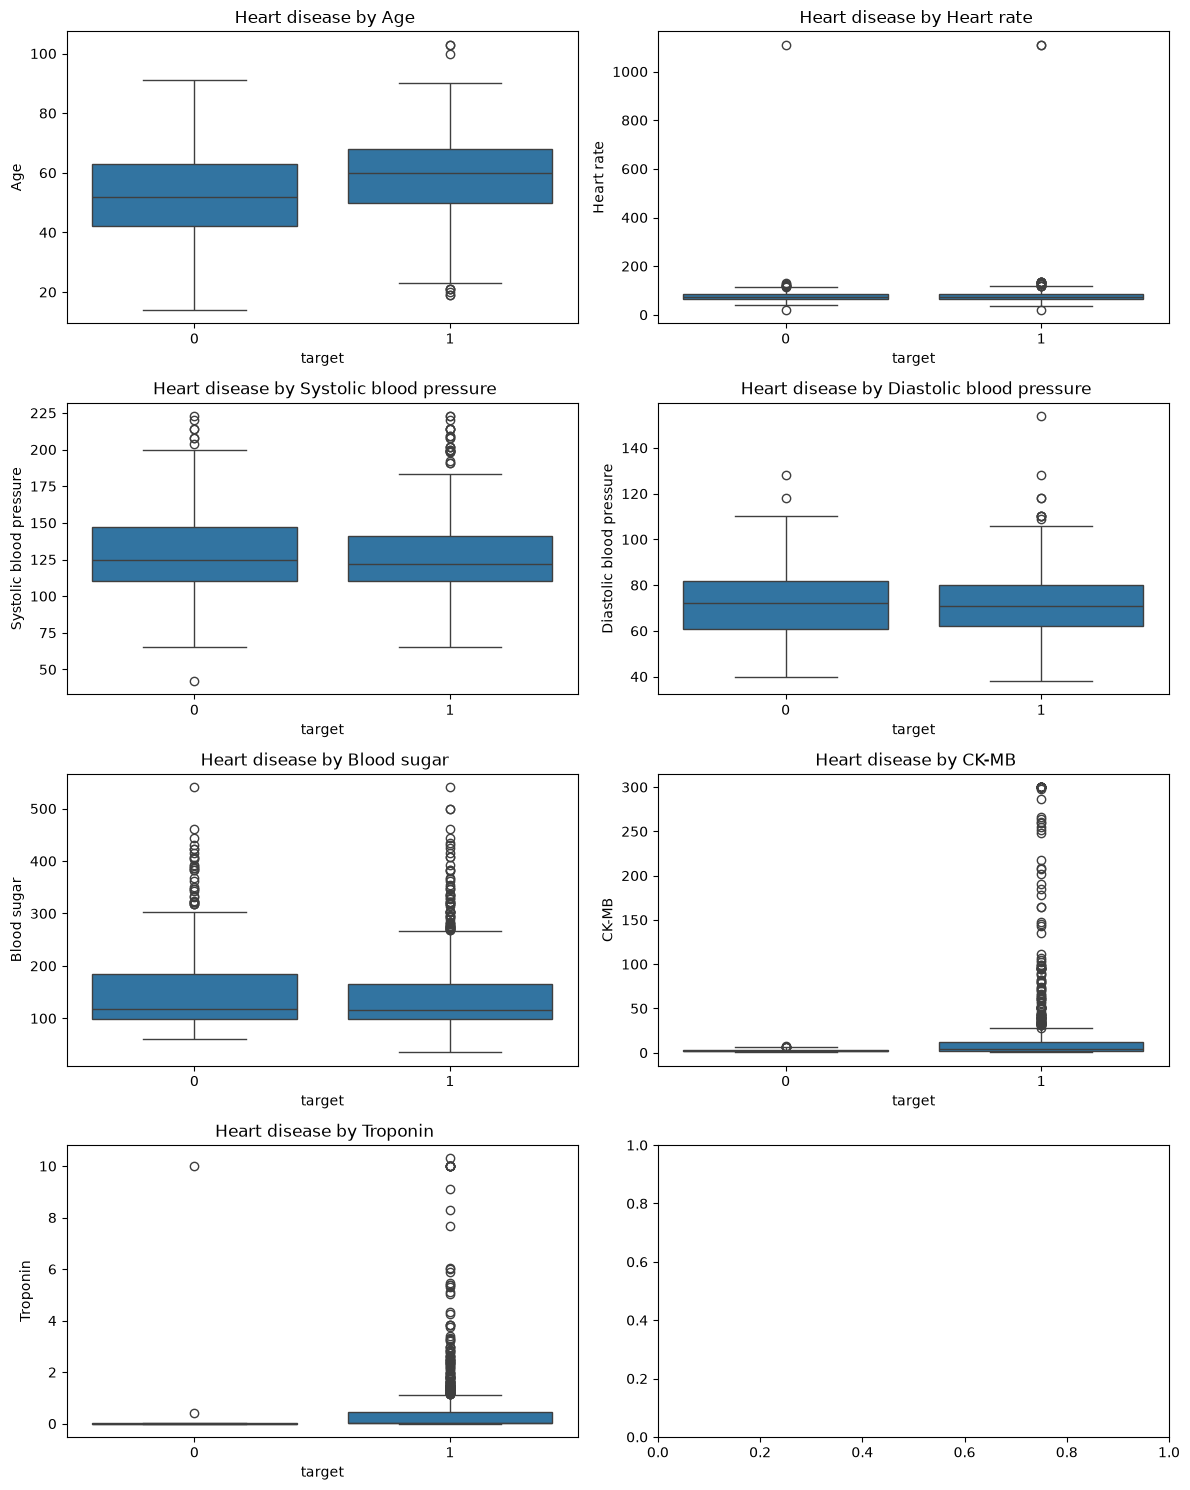

In [14]:
vars=heart.drop(columns=['target','Gender']).columns
n_cols=2
n_rows=4

fig,axes=plt.subplots(n_rows,n_cols,figsize=(12,15))
axes=axes.flatten()

for ax,var in zip(axes,vars):
    sns.boxplot(heart,x='target',y=var,ax=ax)
    ax.set_title(f" Heart disease by {var}")

plt.tight_layout()
plt.show()

Conclusiones sacadas a partir de los boxplots:

-**Age**: parece ser que la edad es un factor influyente en el desarrollo de enfermedades cardíacas. Para valores altos, mas probabilidad de tenerla.
-**Heart rate**: existen valores por encima de 1.000 en el pulso. Esto se debe a erratas y por tanto deben ser eliminadas.
-**Systolic blood pressure**: lo mismo ocurre con el valor extremo en este caso. Eliminaremos el valor este por ser con probabilidad muy alta, un error de medición.
--**Troponina** : parece ser que los valores extremos elevados están relacionadas con las enfermedades.

In [16]:
#Eliminemos por tanto los ouliers

heart=heart[heart['Heart rate']<250]
heart=heart[heart['Systolic blood pressure']>50]

Veamos ahora si la variable genero tiene algo que ver, utilizando un groupby y generando un dataframe.

In [17]:
genero=heart.groupby(['target','Gender'],as_index=False).agg(N=('Blood sugar','size'))
genero

,target,Gender,N
0,0,0,201
1,0,1,306
2,1,0,246
3,1,1,562


Parece ser que la variable de sexo influye bastante en el desarrollo de una enfermedad cardíaca. A continuación, guardaremos el csv más limpio dentro de data/processed.

In [18]:
heart.to_csv("../data/processed/clean_heart.csv")